In [45]:
import os
import re
import pickle

import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.inception_v3 import InceptionV3
from tensorflow.keras.models import Model
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, LSTM, Embedding, add
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler
from tensorflow.keras.models import load_model

from nltk.translate.bleu_score import corpus_bleu

from sklearn.model_selection import train_test_split

from PIL import Image
from tqdm import tqdm
from tqdm import tqdm_notebook

**Load image descriptions**

In [46]:
images_directory = r'E:\Artificial Intelligence\Projects\Image Caption Generator\data\Images'

captions_path = r'E:\Artificial Intelligence\Projects\Image Caption Generator\data\captions.txt'

def load_captions(file_path):
    with open(file_path, 'r') as f:
        # Store each line in a list
        captions = f.readlines()

        # Lowercase the captions
        captions = [caption.lower() for caption in captions[1:]]

        return captions

captions = load_captions(captions_path)
captions[:15:3]

['1000268201_693b08cb0e.jpg,a child in a pink dress is climbing up a set of stairs in an entry way .\n',
 '1000268201_693b08cb0e.jpg,a little girl climbing the stairs to her playhouse .\n',
 '1001773457_577c3a7d70.jpg,a black dog and a tri-colored dog playing with each other on the road .\n',
 '1001773457_577c3a7d70.jpg,two dogs on pavement moving toward each other .\n',
 '1002674143_1b742ab4b8.jpg,a small girl in the grass plays with fingerpaints in front of a white canvas with a rainbow on it .\n']

**Clean captions**

In [47]:
def clean_text(text):
    # Remove punctuations
    text = re.sub(r'[^\w\s]', '', text)

    # Removes numbers
    text = re.sub(r'\d+', '', text)

    # Removes multiple spaces with a single space & removes leading/trailing spaces
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

# Obtain only the cleaned caption
cleaned_captions = [clean_text(caption.split(',')[1]) for caption in captions]

cleaned_captions[:15:3]

['a child in a pink dress is climbing up a set of stairs in an entry way',
 'a little girl climbing the stairs to her playhouse',
 'a black dog and a tricolored dog playing with each other on the road',
 'two dogs on pavement moving toward each other',
 'a small girl in the grass plays with fingerpaints in front of a white canvas with a rainbow on it']

**Refine the captions & merge with image info**

In [48]:
captions_IDs= []

for i in range(len(cleaned_captions)):
    # Merge images with cleaned captions and add start and end tokens to 
    # captions to define sentence boundaries
    item = captions[i].split(',')[0]+'\t'+'start '+cleaned_captions[i]+' end\n'
    captions_IDs.append(item)

captions_IDs[:20:3]

# The start/end tokens are important during training so the decoder learns
# when to start generating a caption and when to stop generating it

['1000268201_693b08cb0e.jpg\tstart a child in a pink dress is climbing up a set of stairs in an entry way end\n',
 '1000268201_693b08cb0e.jpg\tstart a little girl climbing the stairs to her playhouse end\n',
 '1001773457_577c3a7d70.jpg\tstart a black dog and a tricolored dog playing with each other on the road end\n',
 '1001773457_577c3a7d70.jpg\tstart two dogs on pavement moving toward each other end\n',
 '1002674143_1b742ab4b8.jpg\tstart a small girl in the grass plays with fingerpaints in front of a white canvas with a rainbow on it end\n',
 '1003163366_44323f5815.jpg\tstart a man lays on a bench while his dog sits by him end\n',
 '1003163366_44323f5815.jpg\tstart a shirtless man lies on a park bench with his dog end\n']

**Load sample images with captions**

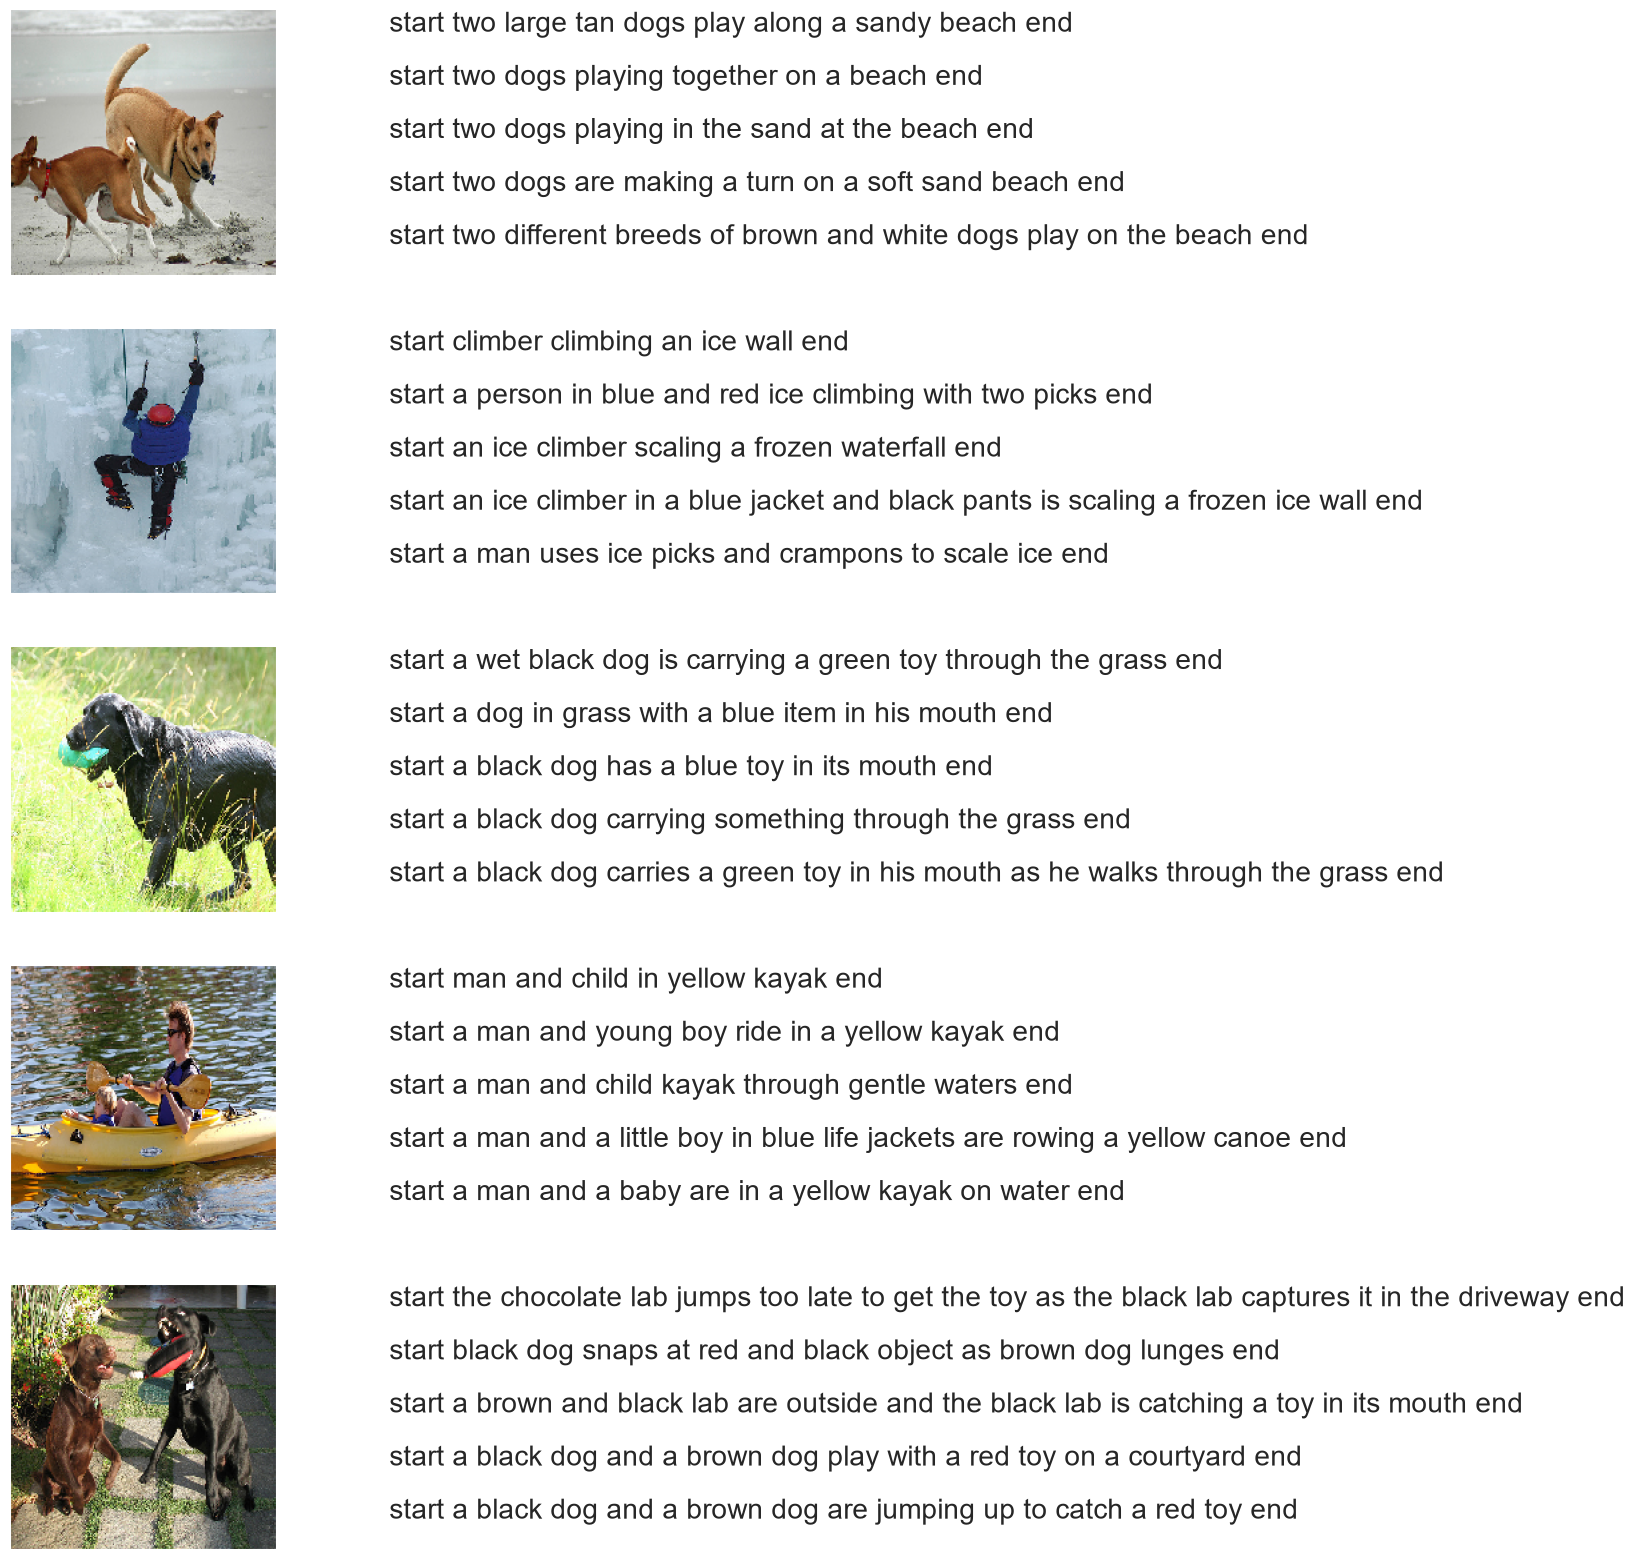

In [49]:
# Verify that the image-caption pairs are correct before proceeding with 
# preprocessing and model training

def visualization(data, num_of_images):
    captions_dictionary = {}

    for item in data[100:100+(num_of_images)*5]:
        image_id, caption = item.split('\t')
        
        if image_id not in captions_dictionary:
            captions_dictionary[image_id] = []
            
        captions_dictionary[image_id].append(caption)

    else:
        list_captions = [x for x in captions_dictionary.items()]

    count = 1
    fig = plt.figure(figsize=(10, 20))

    for filename in list(captions_dictionary.keys()):
        captions = captions_dictionary[filename]
        full_image_path = os.path.join(images_directory, filename)
        image_load = load_img(full_image_path, target_size=(199, 199, 3))

        ax = fig.add_subplot(num_of_images,2,count,xticks=[],yticks=[])
        ax.imshow(image_load)
        count += 1

        ax = fig.add_subplot(num_of_images,2,count)
        plt.axis('off')
        ax.plot()
        ax.set_xlim(0,1)
        ax.set_ylim(0,len(captions))
        for i, caption in enumerate(captions):
            ax.text(0,i,caption,fontsize=20)
        count += 1
    plt.show()

visualization(captions_IDs, 5)

**Exploring the caption length distribution**

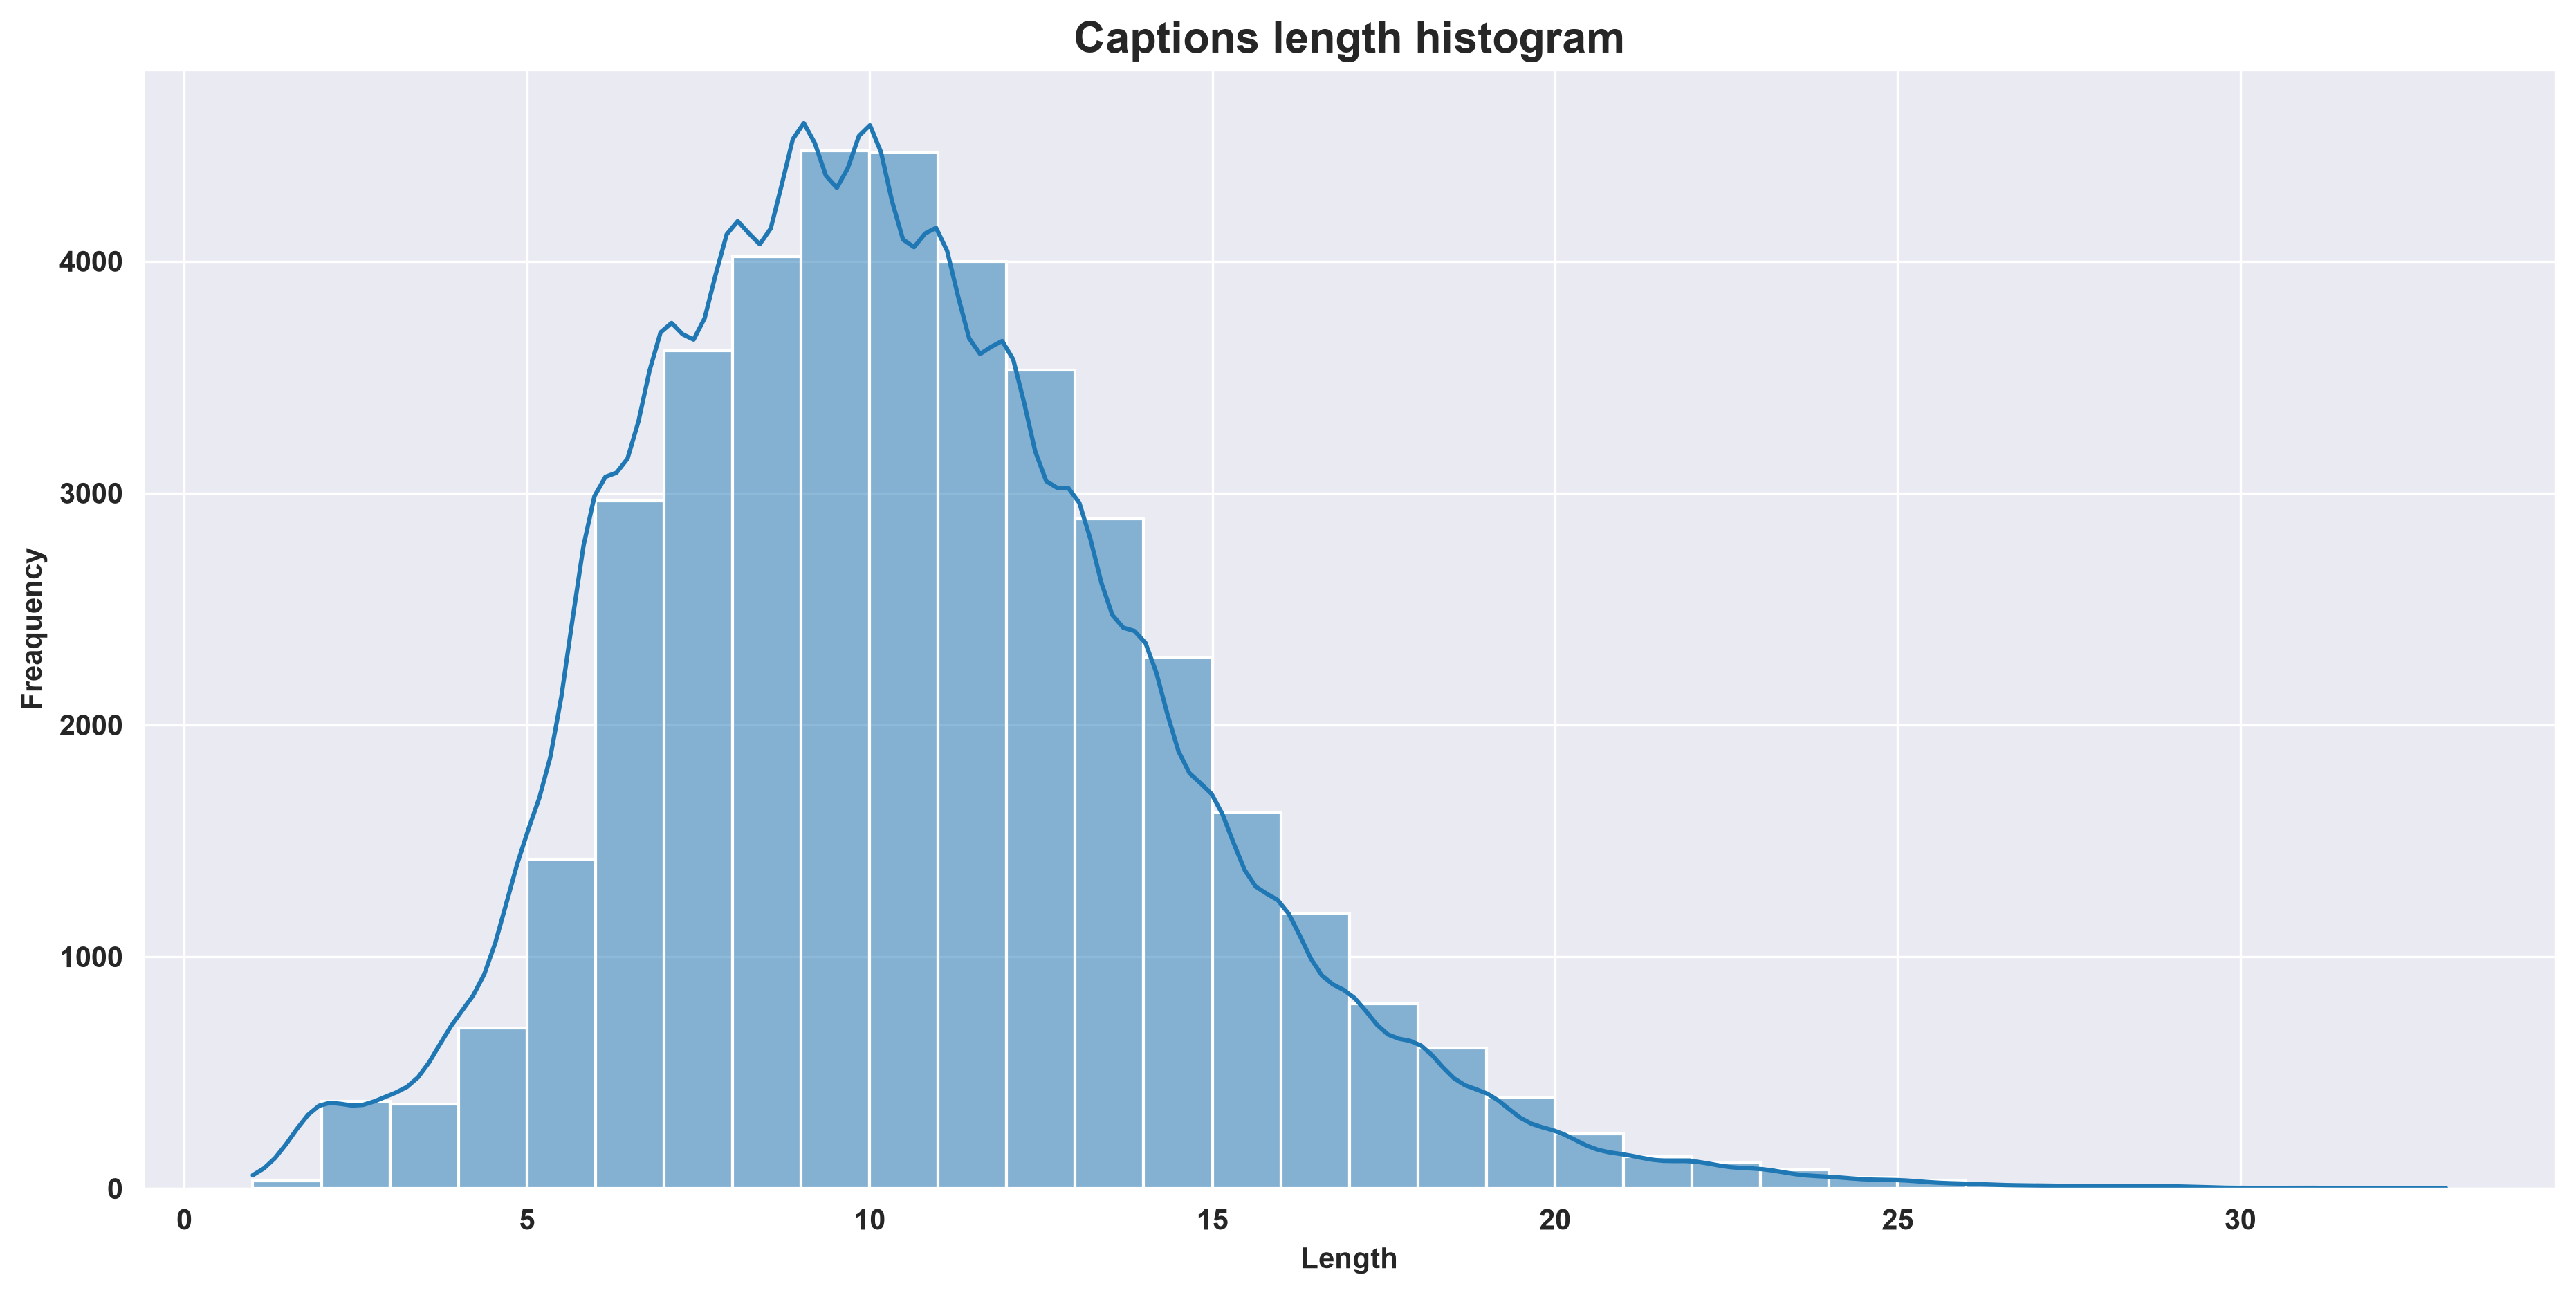

In [50]:
# Analyze the length of captions to determine an optimal sequence length
def captions_length(data):
    plt.figure(figsize=(15, 7), dpi=300)
    sns.set_style('darkgrid')
    sns.histplot(x=[len(x.split(' ')) for x in data], kde=True, binwidth=1)
    plt.title('Captions length histogram', fontsize=15, fontweight='bold')
    plt.xticks(fontweight='bold')
    plt.yticks(fontweight='bold')
    plt.xlabel('Length', fontweight='bold')
    plt.ylabel('Freaquency', fontweight='bold')
    plt.show()

captions_length(cleaned_captions)

**Tokenize vocabulary**

In [51]:
def tokenize_captions(captions):
    tokenizer = Tokenizer()

    # Build vocabulary i.e: assign each unique word an integer ID
    tokenizer.fit_on_texts(captions)
    
    return tokenizer

tokenizer = tokenize_captions(cleaned_captions)
vocab_size = len(tokenizer.word_index) + 1
vocab_size

8586

**Splitting the data into train, validation and test sets**

In [52]:
# All image filenames
all_image_ids = os.listdir(images_directory)

# 85% train images, 15% validation images
train_image_ids, val_image_ids = train_test_split(all_image_ids, test_size=0.15, random_state=42)

# 15% split further into 90% validation images (13.5% overall) and 10% test images (1.5% overall)
val_image_ids, test_image_ids = train_test_split(val_image_ids, test_size=0.1, random_state=42)

# So in total 85% train, 13.5% validation, 1.5% test

train_captions, val_captions, test_captions = [], [], []

# Add each caption to the list of its corresponding set
for caption in captions_IDs:
    image_id, _ = caption.split('\t')

    if image_id in train_image_ids:
        train_captions.append(caption)

    elif image_id in val_image_ids:
        val_captions.append(caption)

    elif image_id in test_image_ids:
        test_captions.append(caption)

    else:
        print("Unknown image ID!")

print(len(train_captions)/5)
print(len(val_captions)/5)
print(len(test_captions)/5)

6877.0
1092.0
122.0


**Create function for extraction of feature vectors of each images**

In [53]:
# Using transfer learning via a pre-trained model (Inception V3) to extract image features
def preprocess_image(image_path):
    # InceptionV3 model expects the image in 299x299 (x3 RGB channels) pixels so we resize it
    img = load_img(image_path, target_size=(299, 299))

    # Convert image to numerical array
    img = img_to_array(img)

    # Adding batch dimension as NN expects a batch of images
    # so (299, 299, 3) becomes (x, 299, 299, 3) i.e: x images in the batch
    img = np.expand_dims(img, axis=0)

    # InceptionV3 model preprocessing
    img = tf.keras.applications.inception_v3.preprocess_input(img)
    return img

def extract_image_features(model, image_path):
    img = preprocess_image(image_path)
    features = model.predict(img, verbose=0)
    return features

**Load InceptionV3 model**

In [54]:
# Load InceptionV3 with weights learned from ImageNet
inception_v3_model = InceptionV3(weights='imagenet', input_shape=(299, 299, 3))

# Removing final classification layer from the original CNN
inception_v3_model.layers.pop()

# Create a new model which outputs the learned image features from an earlier layer
inception_v3_model=Model(inputs=inception_v3_model.inputs, outputs=inception_v3_model.layers[-2].output)

# The output is a 2048-dimensional vector which is a learned representation of the images
# we will input

**Extracting image features for training, validation & testing**

In [ ]:
# This step involves inputting each image in our dataset into the InceptionV3 model to extract its feature vector

# Each dictionary holds a 2048-dimensional feature vector for an image
train_img_features, val_img_features, test_img_features = {}, {}, {}

# Progress bar
pbar = tqdm(total=len(all_image_ids), position=0, leave=True, colour='green')

for filename in all_image_ids:
    # Construct image path
    image_id = filename.split('\t')[0]
    image_path = os.path.join(images_directory, image_id)

    # Extract features
    image_features = extract_image_features(inception_v3_model, image_path)

    # Insert image name & its feature vector in corresponding dict
    if image_id in train_image_ids:
        train_img_features[image_id]=image_features.flatten()
        pbar.update(1)

    elif image_id in val_image_ids:
        val_img_features[image_id]=image_features.flatten()
        pbar.update(1)

    elif image_id in test_image_ids:
        test_img_features[image_id]=image_features.flatten()
        pbar.update(1)

    else:
        print("Unknown image ID!")

pbar.close()

  3%|▎         | 261/8091 [00:28<15:13,  8.58it/s]Exception ignored in: <function tqdm.__del__ at 0x0000015ED8E7B9C0>
Traceback (most recent call last):
  File "e:\Artificial Intelligence\Projects\Image Caption Generator\.venv\Lib\site-packages\tqdm\std.py", line 1154, in __del__
    self.close()
  File "e:\Artificial Intelligence\Projects\Image Caption Generator\.venv\Lib\site-packages\tqdm\notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
AttributeError: 'tqdm_notebook' object has no attribute 'disp'
100%|██████████| 8091/8091 [14:06<00:00,  9.56it/s]


**Save/load extracted features in a pickle file**

In [20]:
# Save extracted features
with open("train_image_features.pkl", "wb") as f:
    pickle.dump(train_img_features, f)

with open("val_image_features.pkl", "wb") as f:
    pickle.dump(val_img_features, f)

with open("test_image_features.pkl", "wb") as f:
    pickle.dump(test_img_features, f)

In [55]:
# Load extracted features
with open("../variables/train_image_features.pkl", "rb") as f:
    train_img_features = pickle.load(f)

with open("../variables/val_image_features.pkl", "rb") as f:
    val_img_features = pickle.load(f)

with open("../variables/test_image_features.pkl", "rb") as f:
    test_img_features = pickle.load(f)

**Creating a data generator for model training**

In [56]:
def data_generator(captions, image_features, tokenizer, max_caption_length, batch_size):
    # Total number of captions: 8091 images * 5 captions = 40,455
    num_samples = len(captions)

    # Generator produces batches until epochs finish
    while True:
        # Shuffle image-caption pairs
        shuffled_captions = np.random.permutation(captions)

        # Iterate through captions batch by batch
        for start_idx in range(0, num_samples, batch_size):
            end_idx = min(start_idx + batch_size, num_samples)

            # Data for current batch
            # X_images: image feature vectors
            # X_captions: caption sequences/input text
            # y: target next words
            X_images, X_captions, y = [], [], []

            # Iterate through each caption in current batch
            for caption in shuffled_captions[start_idx:end_idx]:
                # Split images & captions
                image_id, caption_text = caption.split('\t')
                caption_text = caption_text.rstrip('\n')

                # Tokenize the caption with the tokenizer we fit earlier on our vocabulary
                seq = tokenizer.texts_to_sequences([caption_text])[0]

                # Iterate over a single caption to create input-target pairs
                for i in range(1, len(seq)):
                    # Set input and corresponding target
                    in_seq, out_seq = seq[:i], seq[i]

                    # 0-pad input sequences, total length after padding is equivalent to max caption length
                    in_seq = pad_sequences([in_seq], maxlen = max_caption_length)[0]

                    # One-hot encode output token, total length is size of vocabulary
                    out_seq = to_categorical(out_seq, num_classes = vocab_size)

                    X_images.append(image_features[image_id])
                    X_captions.append(in_seq)
                    y.append(out_seq)

            # Yield sends the current batch to the model without ending the generator
            yield (np.array(X_images), np.array(X_captions)), np.array(y)

max_caption_length = max(len(caption.split()) for caption in cleaned_captions) + 1
batch_size_train = 270
batch_size_val = 150

train_data_generator = data_generator(train_captions, train_img_features, tokenizer, max_caption_length, batch_size_train)
val_data_generator = data_generator(val_captions, val_img_features, tokenizer, max_caption_length, batch_size_val)

**Building model**

In [57]:
def build_model(vocab_size, max_caption_length, cnn_output_dim):
    input_image = Input(shape=(cnn_output_dim,), name='Features_Input')
    fe1 = BatchNormalization()(input_image)
    fe2 = Dense(256, activation='relu')(fe1)
    fe3 = BatchNormalization()(fe2)

    input_caption = Input(shape=(max_caption_length,), name='Sequence_Input')
    se1 = Embedding(vocab_size, 256, mask_zero=True)(input_caption)
    se2 = LSTM(256)(se1)

    decoder1 = add([fe3, se2])
    decoder2 = Dense(256, activation='relu')(decoder1)
    outputs = Dense(vocab_size, activation='softmax', name='Output_Layer')(decoder2)

    model = Model(inputs=[input_image, input_caption], outputs=outputs, name='Image_Captioning')

    return model

cnn_output_dim = inception_v3_model.output_shape[1]
caption_model = build_model(vocab_size, max_caption_length, cnn_output_dim)
optimizer = Adam(learning_rate = 0.01, clipnorm = 1.0)

caption_model.compile(loss = 'categorical_crossentropy', optimizer=optimizer)
caption_model.summary()

Model: "Image_Captioning"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Features_Input      │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 2048)      │      8,192 │ Features_Input[0… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sequence_Input      │ (None, 34)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 256)       │    524,544 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 34, 256)   │  2,198,016 │ Sequence_Input[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 34)        │          0 │ Sequence_Input[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 256)       │    525,312 │ embedding_1[0][0… │
│                     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 256)       │          0 │ batch_normalizat… │
│                     │                   │            │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │     65,792 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Output_Layer        │ (None, 8586)      │  2,206,602 │ dense_3[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,529,482 (21.09 MB)

 Trainable params: 5,524,874 (21.08 MB)

 Non-trainable params: 4,608 (18.00 KB)

**Training Model (Performed on Colab)**

In [ ]:
# Implement early stopping to get best validation loss to avoid overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Control learning rate decay
def lr_scheduler(epoch, lr):
    return float(lr * tf.math.exp(-0.6))

lr_schedule = LearningRateScheduler(lr_scheduler)

history = caption_model.fit(train_data_generator,
    steps_per_epoch=len(train_captions)//batch_size_train, # 34,385//270 = ~127 batches per epoch
    validation_data=val_data_generator, 
    validation_steps=len(val_captions)//batch_size_val,    # 5460//150 ~36 batches batches per epoch
    epochs=15, 
    callbacks=[early_stopping, lr_schedule]) 

**Load model**

In [58]:
caption_model = load_model("..\image_captioning_model.keras")

<>:1: SyntaxWarning: invalid escape sequence '\i'
<>:1: SyntaxWarning: invalid escape sequence '\i'
C:\Users\Abid Kazmi\AppData\Local\Temp\ipykernel_13876\3027692049.py:1: SyntaxWarning: invalid escape sequence '\i'
  caption_model = load_model("..\image_captioning_model.keras")


**Greedy generator**

In [59]:
def greedy_generator(image_features):
    in_text = 'start'

    for _ in range(max_caption_length):
        sequence = tokenizer.texts_to_sequences([in_text])[0]
        sequence = pad_sequences([sequence], maxlen=max_caption_length).reshape((1, max_caption_length))

        prediction = caption_model.predict([image_features.reshape(1, cnn_output_dim), sequence], verbose=0)
        idx = np.argmax(prediction)
        word = tokenizer.index_word[idx]
        in_text += ' ' + word
        if word == 'end':
            break

    in_text = in_text.replace('start ', '')
    in_text = in_text.replace(' end', '')

    return in_text

**Beam-search generator**

In [60]:
def beam_search_generator(image_features, K_beams = 3, log = False):
    start = [tokenizer.word_index['start']]
    start_word = [[start, 0.0]]
    for _ in range(max_caption_length):
        temp = []
        for s in start_word:
            sequence  = pad_sequences([s[0]], maxlen=max_caption_length).reshape((1,max_caption_length))
            preds = caption_model.predict([image_features.reshape(1,cnn_output_dim), sequence], verbose=0)
            word_preds = np.argsort(preds[0])[-K_beams:]
            for w in word_preds:
                next_cap, prob = s[0][:], s[1]
                next_cap.append(w)
                if log:
                    prob += np.log(preds[0][w]) # assign a probability to each K words
                else:
                    prob += preds[0][w]
                temp.append([next_cap, prob])
                
        start_word = temp
        start_word = sorted(start_word, reverse=False, key=lambda l: l[1])
        start_word = start_word[-K_beams:]

    start_word = start_word[-1][0]
    captions_ = [tokenizer.index_word[i] for i in start_word]
    final_caption = []
    for i in captions_:
        if i != 'end':
            final_caption.append(i)
        else:
            break
        
    final_caption = ' '.join(final_caption[1:])
    return final_caption

**BLEU score**

In [69]:
def BLEU_score(actual, greedy, beam_search):

    greedy_text = greedy[0]
    beam_text = beam_search[0]

    actual_tokens = [[caption.split() for caption in actual]]
    greedy_tokens = [greedy_text.split()]
    beam_tokens = [beam_text.split()]

    score_greedy_1 = corpus_bleu(
        actual_tokens, greedy_tokens, weights=(1, 0, 0, 0)
    )
    score_greedy_2 = corpus_bleu(
        actual_tokens, greedy_tokens, weights=(0.5, 0.5, 0, 0)
    )

    score_BS_1 = corpus_bleu(
        actual_tokens, beam_tokens, weights=(1, 0, 0, 0)
    )
    score_BS_2 = corpus_bleu(
        actual_tokens, beam_tokens, weights=(0.5, 0.5, 0, 0)
    )

    return [
        f'BLEU-2 Greedy: {round(score_greedy_2, 5)}',
        f'BLEU-1 Greedy: {round(score_greedy_1, 5)}',
        f'Greedy: {greedy_text}',
        f'BLEU-2 Beam Search: {round(score_BS_2, 5)}',
        f'BLEU-1 Beam Search: {round(score_BS_1, 5)}',
        f'Beam Search: {beam_text}'
    ]

**Generating captions for test images**

In [66]:
generated_captions = {}

pbar = tqdm(total=len(test_img_features), position=0, leave=True)
for image_id in test_img_features:
    cap = greedy_generator(test_img_features[image_id])
    generated_captions[image_id] = cap
    pbar.update(1)

pbar.close()

100%|██████████| 122/122 [01:29<00:00,  1.37it/s]


**Collect human captions for testing**

In [67]:
test_actual_captions = {}

for caption in test_captions:
    image_id, cap = caption.split('\t')
    
    if image_id not in test_actual_captions:
        test_actual_captions[image_id] = []
    
    test_actual_captions[image_id].append(cap)

**Visualizing caption generation results**

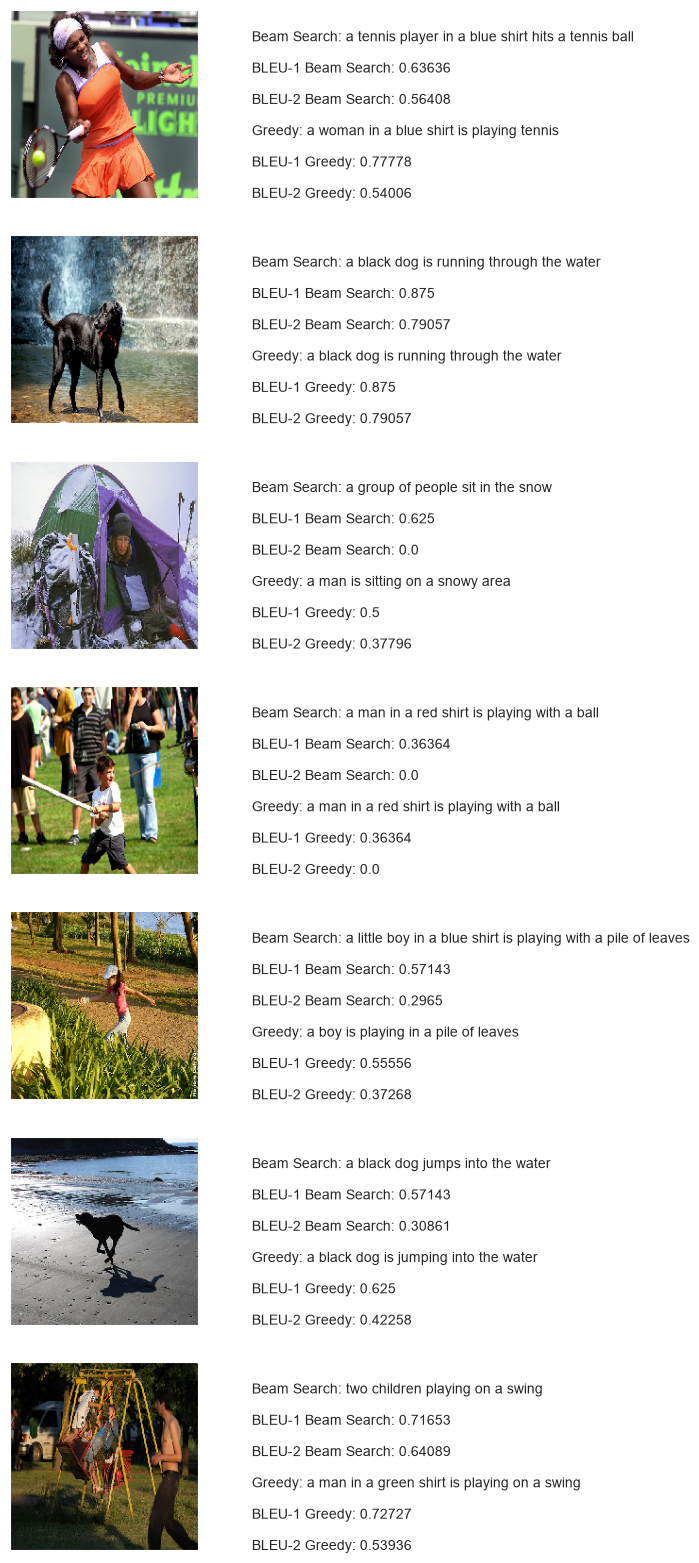

In [71]:
def visualization(data, greedy_caps, beamS_generator, evaluator, num_of_images):
    keys = list(data.keys()) 
    images = [np.random.choice(keys) for i in range(num_of_images)] # Randomly selected images
    count = 1
    fig = plt.figure(figsize=(6,20))
    for filename in images:
        actual_cap = data[filename]
        actual_cap = [x.replace("start ", "") for x in actual_cap]
        actual_cap = [x.replace(" end", "") for x in actual_cap]

        greedy_cap = greedy_caps[filename]
        beamS_cap = beamS_generator(test_img_features[filename])

        caps_with_score = evaluator(actual_cap, [greedy_cap]*(len(actual_cap)), [beamS_cap]*(len(actual_cap)))

        image_load = load_img(
            os.path.join(images_directory, filename),
            target_size=(199, 199, 3)
        )
        ax = fig.add_subplot(num_of_images,2,count,xticks=[],yticks=[])
        ax.imshow(image_load)
        count += 1

        ax = fig.add_subplot(num_of_images,2,count)
        plt.axis('off')
        ax.plot()
        ax.set_xlim(0,1)
        ax.set_ylim(0,len(caps_with_score))
        for i, text in enumerate(caps_with_score):
            ax.text(0,i,text,fontsize=10)
        count += 1
    plt.show()

visualization(test_actual_captions, generated_captions, beam_search_generator, BLEU_score, 7)

**Test on own image**

In [ ]:
image_path = r""
image_features = extract_image_features(inception_v3_model, image_path)
image_features = image_features.flatten()

caption = beam_search_generator(image_features)

plt.figure(figsize=(8, 6))
plt.imshow(Image.open(image_path))
plt.axis('off')
plt.title(caption)
plt.show()